## Setup

In [1]:
# Load libraries and the API key from .env
import base64
from dotenv import load_dotenv
load_dotenv()

from anthropic import Anthropic
from anthropic.types import Message

# Create the client and choose the model
client = Anthropic()
model = "claude-haiku-4-5"

## Helper functions

In [2]:
# Add a user turn; accepts text, a list of blocks, or a Message
def add_user_message(messages, message):
    messages.append({
        "role": "user",
        "content": message.content if isinstance(message, Message) else message,
    })

# Add an assistant turn
def add_assistant_message(messages, message):
    messages.append({
        "role": "assistant",
        "content": message.content if isinstance(message, Message) else message,
    })

# Send the conversation to Claude and return the full message
def chat(messages, system=None, temperature=1.0):
    params = {
        "model": model,
        "max_tokens": 1500,
        "messages": messages,
        "temperature": temperature,
    }
    if system:
        params["system"] = system
    return client.messages.create(**params)

# Extract only the text from a response
def text_from_message(message):
    return "\n".join(b.text for b in message.content if b.type == "text")

## Load an image as base64

In [3]:
# Read the image file and encode it as base64 text
def load_image(path):
    with open(path, "rb") as f:
        return base64.standard_b64encode(f.read()).decode("utf-8")

# Build an image block the API understands
def image_block(path, media_type="image/png"):
    return {
        "type": "image",
        "source": {
            "type": "base64",
            "media_type": media_type,  # use image/jpeg for .jpg files
            "data": load_image(path),
        },
    }

## Install Pillow

In [4]:
# Pillow draws and reads images
%pip install pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Generate marble images with a known count

In [5]:
import random
from PIL import Image, ImageDraw

# Draw a given number of non-overlapping coloured circles on a white canvas
def make_marbles(path, count, size=500, radius=25, seed=0):
    random.seed(seed)  # fixed seed makes the image repeatable
    img = Image.new("RGB", (size, size), "white")
    draw = ImageDraw.Draw(img)
    centers = []
    attempts = 0
    while len(centers) < count and attempts < 10000:
        attempts += 1
        x = random.randint(radius, size - radius)
        y = random.randint(radius, size - radius)
        # Keep circles apart so they never overlap
        if all((x - cx) ** 2 + (y - cy) ** 2 > (2 * radius + 4) ** 2 for cx, cy in centers):
            centers.append((x, y))
            color = tuple(random.randint(30, 220) for _ in range(3))
            draw.ellipse([x - radius, y - radius, x + radius, y + radius], fill=color)
    img.save(path)
    return len(centers)

# example.png has 11 marbles, target.png has 12, image.png has 12
print(make_marbles("example.png", 11, seed=1))
print(make_marbles("target.png", 12, seed=2))
print(make_marbles("image.png", 12, seed=3))

11
12
12


The function prints how many circles it actually drew, which is your confirmed ground truth. Open the PNG files in your folder to see them.

## Generate a simple property image

In [6]:
# Draw a crude top-down "satellite" view: a roof, a driveway, and tree canopies
def make_property(path, size=600, seed=5):
    random.seed(seed)
    img = Image.new("RGB", (size, size), (60, 110, 50))  # green ground
    draw = ImageDraw.Draw(img)

    # Driveway and house roof
    draw.rectangle([270, 400, 330, 600], fill=(150, 150, 150))
    draw.rectangle([200, 220, 400, 400], fill=(150, 80, 60))

    # Dark tree canopies, some deliberately overhanging the roof
    trees = [(210, 230, 60), (390, 240, 55), (300, 180, 50),
             (120, 300, 70), (480, 320, 70), (150, 480, 60), (470, 480, 60)]
    for x, y, r in trees:
        draw.ellipse([x - r, y - r, x + r, y + r], fill=(20, 70, 25))
    img.save(path)

make_property("property.png")

## Check the generated images

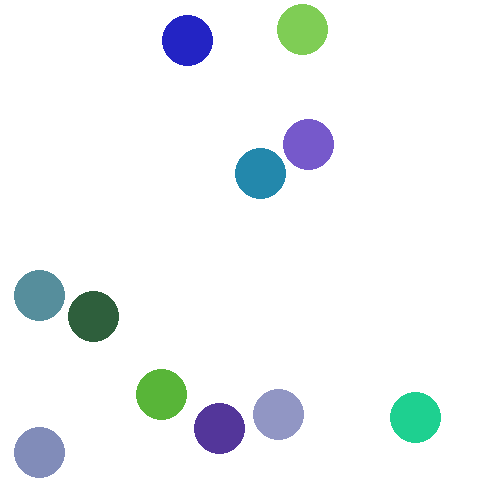

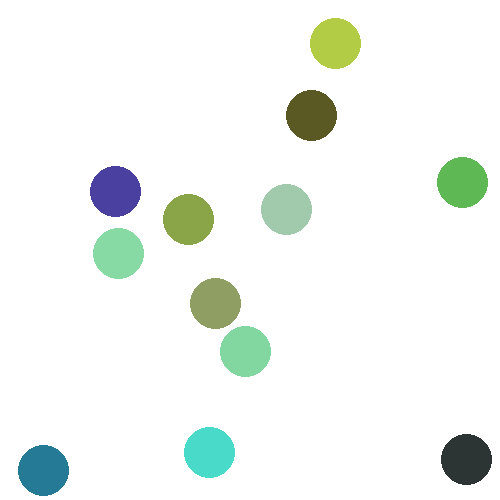

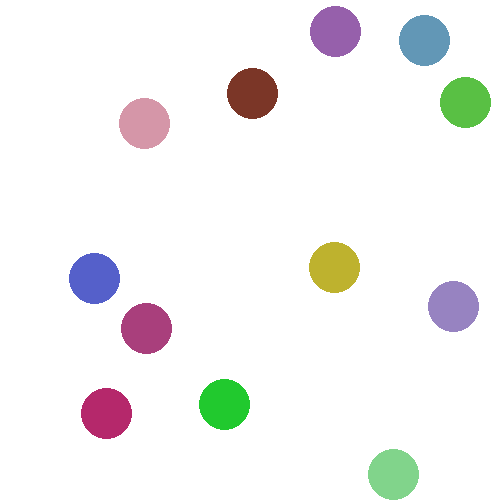

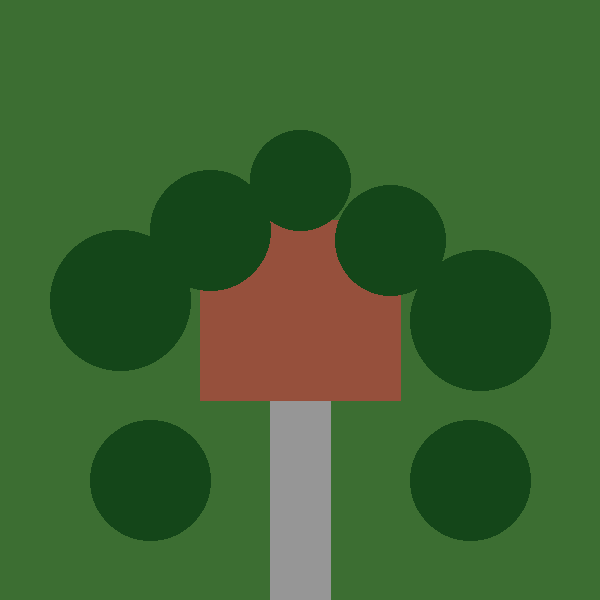

In [7]:
# Show the images inside the notebook
from IPython.display import display

for name in ["example.png", "target.png", "image.png", "property.png"]:
    display(Image.open(name))

## Simple question with an image

In [8]:
# Send an image block and a text block in the same user message
messages = []
add_user_message(messages, [
    image_block("image.png"),
    {"type": "text", "text": "What do you see in this image?"},
])

response = chat(messages)
print(text_from_message(response))

# Image Description

I see a collection of **12 colored circles** scattered across a white background in an irregular pattern. Here's what I observe:

**Colors present:**
- Pink/Mauve
- Dark brown/Maroon
- Purple
- Blue (dark and light shades)
- Green (bright and light/mint shades)
- Yellow-green/Olive
- Magenta/Hot pink
- Light purple/Lavender

**Arrangement:**
The circles are distributed unevenly across the image, with:
- Several concentrated in the upper portion
- A few scattered in the middle and lower sections
- No apparent geometric pattern or regular spacing
- Varying sizes (though mostly similar)

The overall composition creates a casual, decorative, or perhaps abstract artistic arrangement.


## Step-by-step prompt for counting

In [9]:
# A methodology prompt improves accuracy on tasks like counting
count_prompt = """
Analyze this image of marbles and determine the exact count using this methodology:
1. Begin by identifying each unique marble one at a time. Assign each a number as you identify it.
2. Verify your result by counting with a different method. Start from the bottom-left corner and work row by row, from left to right.

What is the exact, verified number of marbles in this image?
"""

messages = []
add_user_message(messages, [
    image_block("image.png"),
    {"type": "text", "text": count_prompt},
])
print(text_from_message(chat(messages)))

I'll count the marbles using both methods to ensure accuracy.

## Method 1: Identifying each unique marble individually

1. Pink marble (upper left area)
2. Dark brown/maroon marble (upper middle)
3. Purple marble (upper right area)
4. Blue marble (upper right)
5. Green marble (right side)
6. Blue marble (left side, middle)
7. Magenta/pink marble (left-center)
8. Yellow-green marble (center-right)
9. Purple marble (right side, middle-lower)
10. Magenta marble (lower left)
11. Green marble (lower center)
12. Light green/mint marble (lower right)

**Method 1 Count: 12 marbles**

## Method 2: Counting from bottom-left, row by row, left to right

**Bottom row:** Magenta marble (left), Green marble (center), Light green marble (right) = 3 marbles

**Middle row:** Blue marble (left), Magenta marble (left-center), Yellow-green marble (center-right), Purple marble (right) = 4 marbles

**Upper row:** Pink marble (left), Dark brown marble (center), Purple marble (center-right), Blue marble (righ

## One-shot example with two images

In [10]:
# Show one image with a known answer, then ask about a second image
# (save the files as example.png and target.png)
messages = []
add_user_message(messages, [
    image_block("example.png"),
    {"type": "text", "text": "This image has 11 marbles."},
    image_block("target.png"),
    {"type": "text", "text": "How many marbles are in this second image?"},
])
print(text_from_message(chat(messages)))

I count **11 marbles** in the second image.


## Fire risk assessment prompt

In [11]:
# A structured, step-by-step prompt for analysing a satellite image
fire_prompt = """
Analyze the attached satellite image of a property with these specific steps:

1. Residence identification: Locate the primary residence on the property by looking for:
   - The largest roofed structure
   - Typical residential features (driveway connection, regular geometry)
   - Distinction from other structures (garages, sheds, pools)

2. Tree overhang analysis: Examine all trees near the primary residence:
   - Identify any trees whose canopy extends directly over any portion of the roof
   - Estimate the percentage of roof covered by overhanging branches (0-25%, 25-50%, 50-75%, 75%+)
   - Note particularly dense areas of overhang

3. Fire risk assessment: For any overhanging trees, evaluate:
   - Potential wildfire vulnerability (ember catch points, continuous fuel paths to structure)
   - Proximity to chimneys, vents, or other roof openings if visible
   - Areas where branches create a "bridge" between wildland vegetation and the structure

4. Defensible space identification: Assess the property's overall vegetative structure:
   - Identify if trees connect to form a continuous canopy over or near the home
   - Note any obvious fuel ladders (vegetation that can carry fire from ground to tree to roof)

5. Fire risk rating: Based on your analysis, assign a Fire Risk Rating from 1-4:
   - Rating 1 (Low Risk): No tree branches overhanging the roof, good defensible space around the home
   - Rating 2 (Moderate Risk): Minimal overhang (<25% of roof), some separation between tree canopies
   - Rating 3 (High Risk): Significant overhang (25-50% of roof), connected tree canopies, multiple vulnerability points
   - Rating 4 (Severe Risk): Extensive overhang (>50% of roof), dense vegetation against structure

For each item above (1-5), write one sentence summarizing your findings, with your final response being the numerical rating.
"""

## Run the fire risk analysis

In [12]:
# Use a satellite image of a house (save it as property.png)
messages = []
add_user_message(messages, [
    image_block("property.png"),
    {"type": "text", "text": fire_prompt},
])

response = chat(messages, temperature=0.0)  # low temperature keeps the analysis steady
print(text_from_message(response))

# Satellite Image Fire Risk Analysis

1. **Residence Identification**: The primary residence is the rust-colored rectangular structure in the center of the image, distinguished by its regular geometric form and central positioning on the property with a gray trunk-like element (likely a chimney or central support) extending downward.

2. **Tree Overhang Analysis**: Six dark green circular tree canopies surround the residence in a symmetrical pattern—four positioned at the corners/sides of the roof and two lower trees below—with the upper four trees creating approximately 40-50% overhang coverage directly over the roof perimeter and edges.

3. **Fire Risk Assessment**: The overhanging trees create significant vulnerability points, particularly at the roof corners where multiple canopies converge, and the proximity of dense foliage to the structure's edges presents multiple ember catch points and potential ignition pathways during wildfire conditions.

4. **Defensible Space Identificatio

## Estimate the image cost

In [13]:
# The lesson's formula: tokens = (width x height) / 750
from PIL import Image  # install with: %pip install pillow

with Image.open("property.png") as img:
    w, h = img.size
print(f"{w}x{h}px is about {int(w * h / 750)} tokens")
print("Actual usage:", response.usage.input_tokens, "input tokens")

600x600px is about 480 tokens
Actual usage: 953 input tokens
